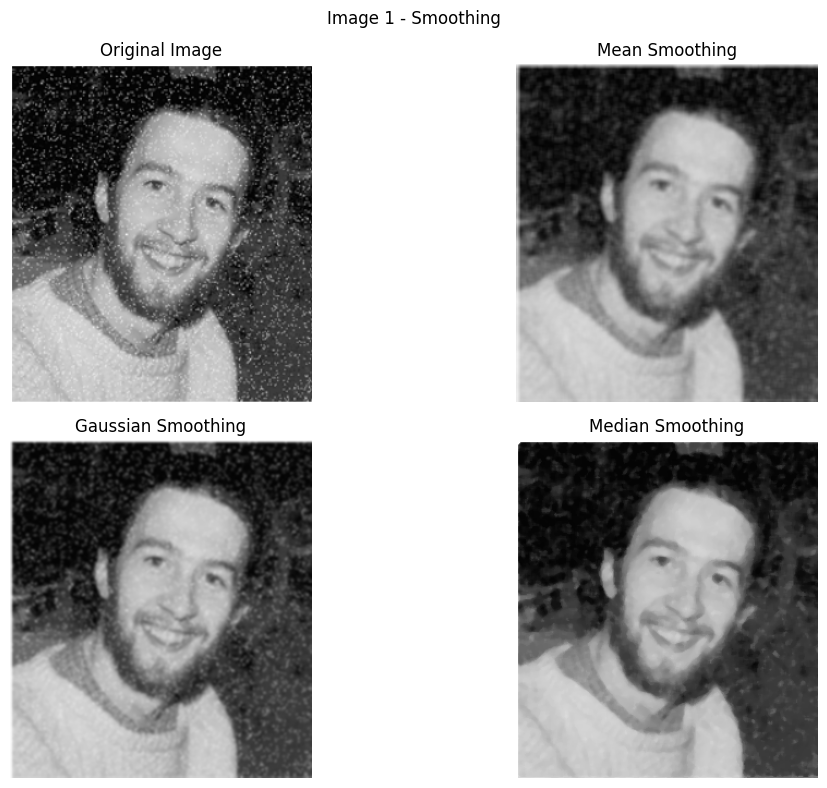

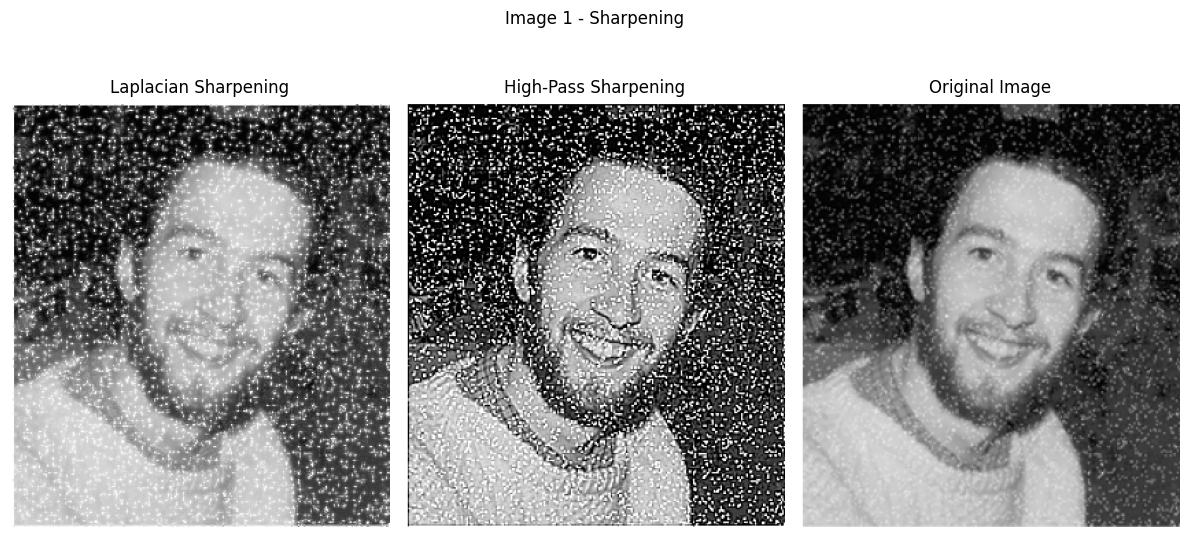

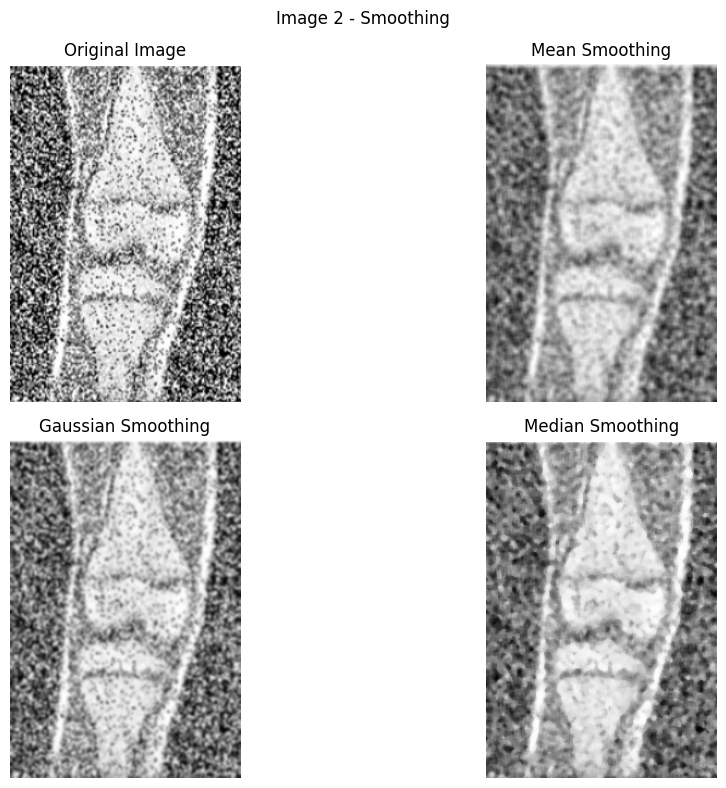

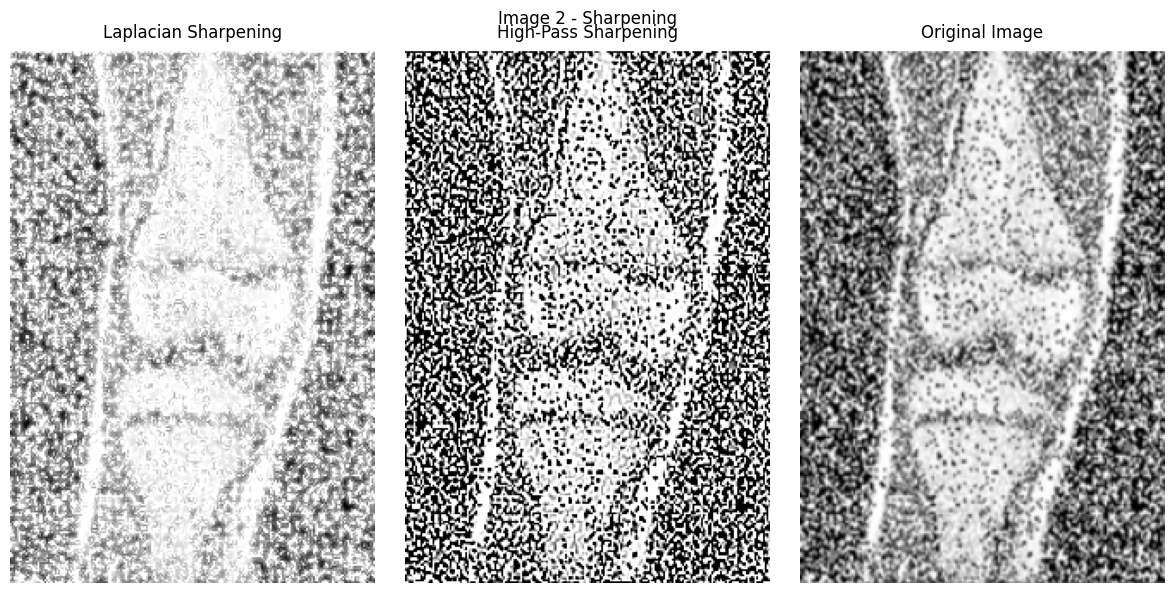

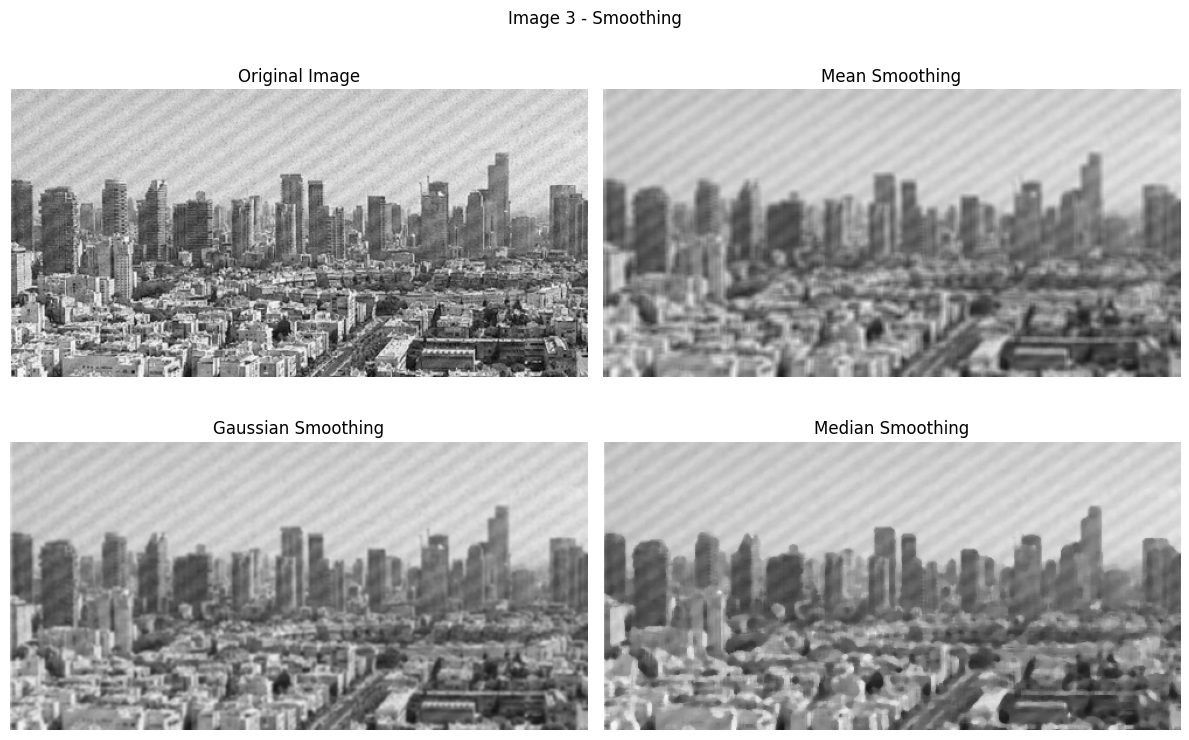

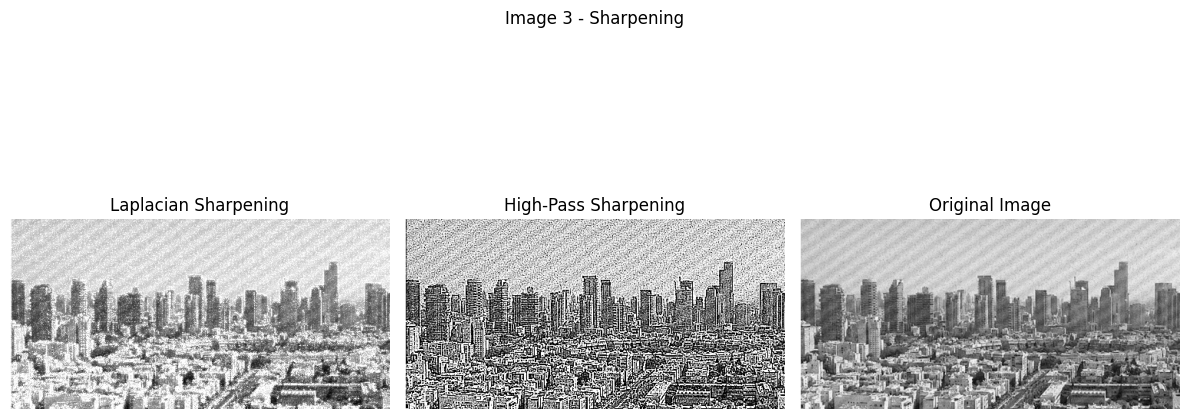

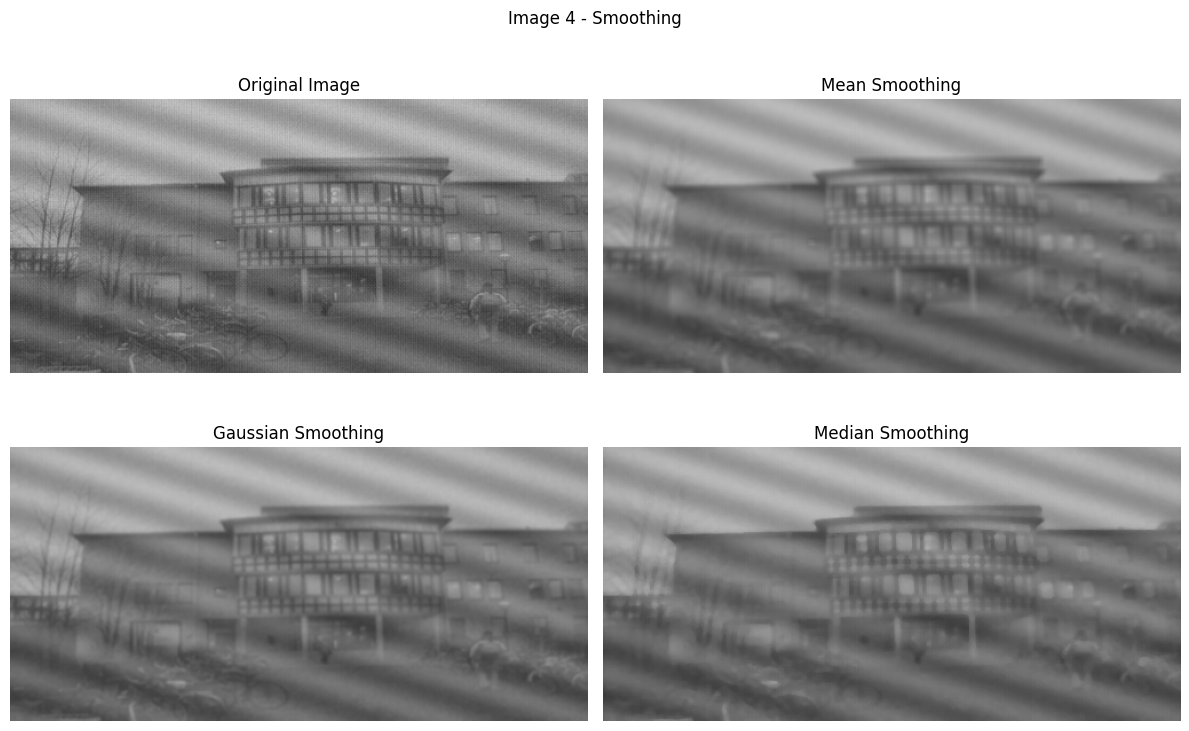

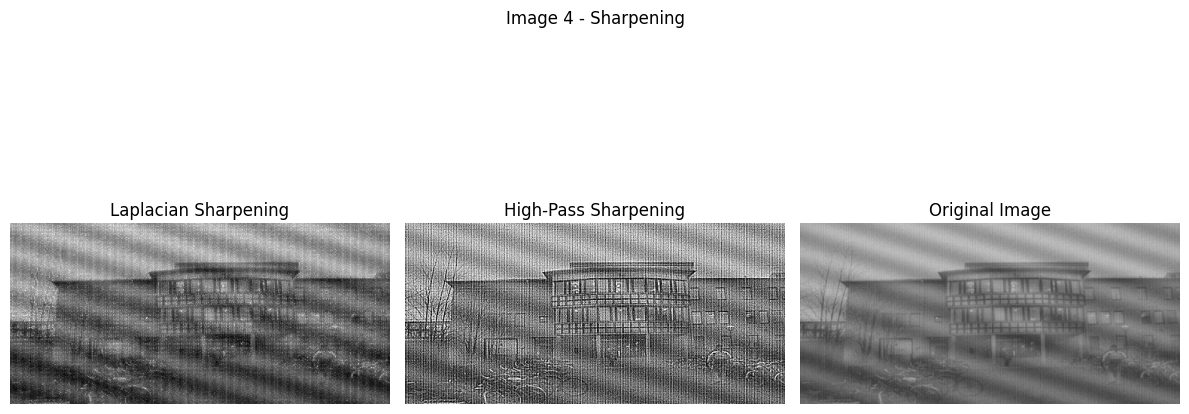

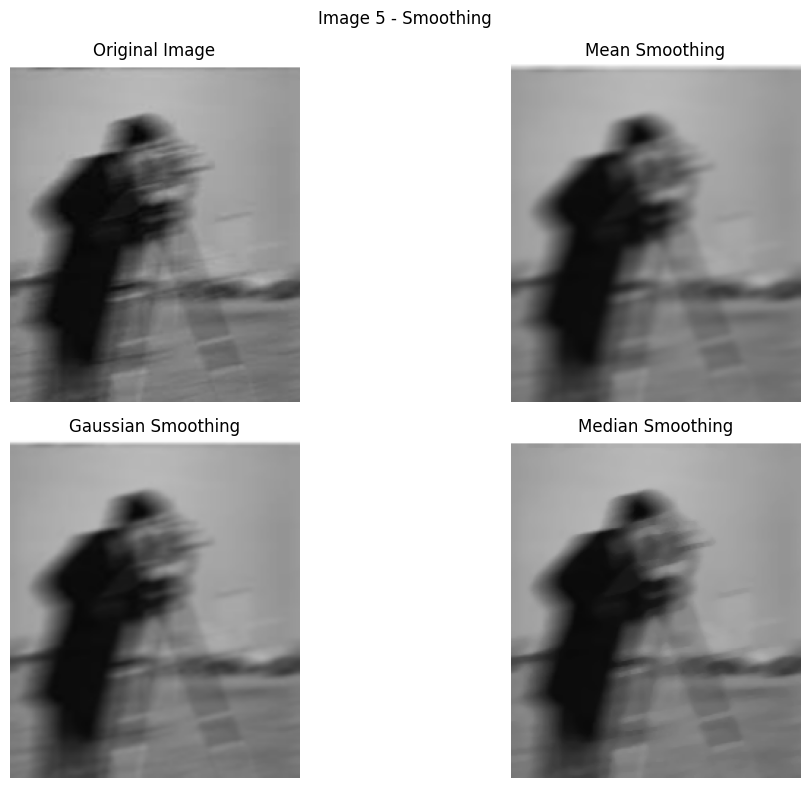

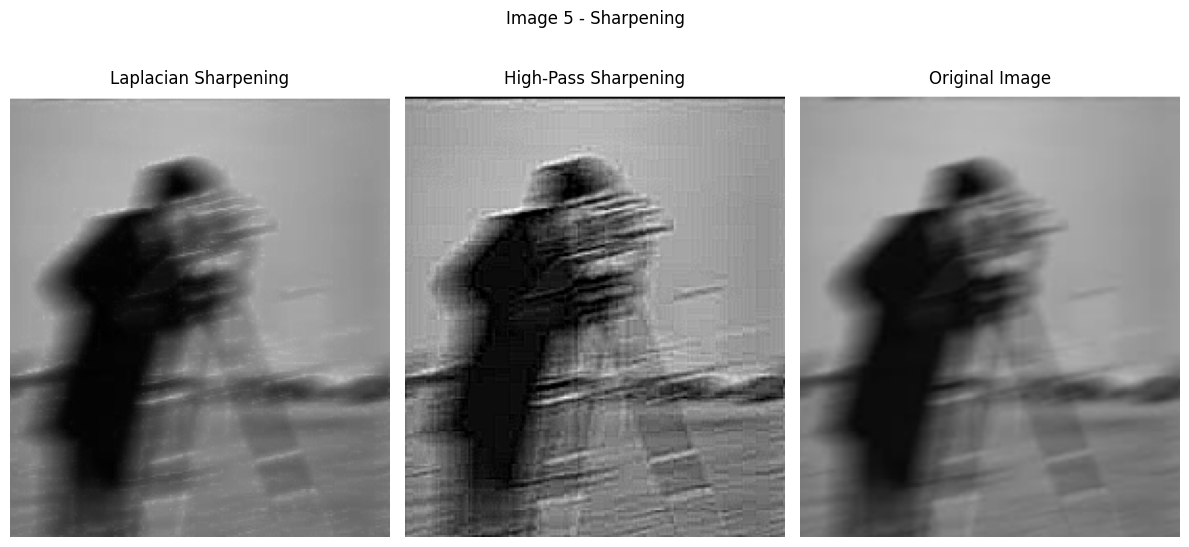

All 5 images processed successfully.


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_paths = [
    r"D:\SEM_5\DSIP\DSIP_practical\open_ended_problem_9\Image1.png",
    r"D:\SEM_5\DSIP\DSIP_practical\open_ended_problem_9\Image2.png",
    r"D:\SEM_5\DSIP\DSIP_practical\open_ended_problem_9\Image3.png",
    r"D:\SEM_5\DSIP\DSIP_practical\open_ended_problem_9\Image4.png",
    r"D:\SEM_5\DSIP\DSIP_practical\open_ended_problem_9\Image5.png"
]

for i, image_path in enumerate(image_paths, 1):

    image = cv2.imread(image_path)

    if image is None:
        print("Image not found:", image_path)
        continue

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mean = cv2.blur(image, (5, 5))

    gaussian = cv2.GaussianBlur(image, (5, 5), 0)

    median = cv2.medianBlur(image, 5)

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    laplacian = cv2.Laplacian(gray, cv2.CV_64F)
    laplacian = cv2.convertScaleAbs(laplacian)

    sharpened = cv2.addWeighted(
        gray, 1, laplacian, 1, 0
    )

    high_pass_kernel = np.array([
        [-1, -1, -1],
        [-1,  9, -1],
        [-1, -1, -1]
    ])

    high_pass = cv2.filter2D(
        image, -1, high_pass_kernel
    )

    plt.figure(figsize=(12, 8))

    plt.subplot(2, 2, 1)
    plt.imshow(image_rgb)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(2, 2, 2)
    plt.imshow(cv2.cvtColor(mean, cv2.COLOR_BGR2RGB))
    plt.title("Mean Smoothing")
    plt.axis("off")

    plt.subplot(2, 2, 3)
    plt.imshow(cv2.cvtColor(gaussian, cv2.COLOR_BGR2RGB))
    plt.title("Gaussian Smoothing")
    plt.axis("off")

    plt.subplot(2, 2, 4)
    plt.imshow(cv2.cvtColor(median, cv2.COLOR_BGR2RGB))
    plt.title("Median Smoothing")
    plt.axis("off")

    plt.suptitle(f"Image {i} - Smoothing")

    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(12, 6))

    plt.subplot(1, 3, 1)
    plt.imshow(sharpened, cmap="gray")
    plt.title("Laplacian Sharpening")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(cv2.cvtColor(high_pass, cv2.COLOR_BGR2RGB))
    plt.title("High-Pass Sharpening")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(image_rgb)
    plt.title("Original Image")
    plt.axis("off")

    plt.suptitle(f"Image {i} - Sharpening")

    plt.tight_layout()
    plt.show()
